In [ ]:
#KMediods mini project(bank customer types)
!pip install scikit-learn-extra
import pandas as pd
from sklearn_extra.cluster import KMedoids
import matplotlib.pyplot as plt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 12.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154569 sha256=9a836af97e0b3cc51a40f22fd2bf4eb5e314724399c91ef62f4928a34db5d3ec
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [14]:
df=pd.read_csv('/content/banking_customer_transaction_segmentation_3000_rows.csv')
df


,Customer_ID,Age,Monthly_Income_INR,Average_Account_Balance_INR,Transactions_Per_Month,Average_Transaction_Amount_INR,Monthly_Spending_INR,Online_Transaction_Ratio,Cash_Transaction_Ratio,Weekend_Transaction_Ratio,Failed_Transactions_Per_Month,Account_Tenure_Years
0,CUST00001,50,43622,151466,22,2325.39,13919,0.305,0.350,0.258,1,3.8
1,CUST00002,48,37901,128538,17,596.68,12672,0.607,0.635,0.095,0,6.2
2,CUST00003,38,51256,104644,49,2529.29,25278,0.670,0.465,0.515,3,5.5
3,CUST00004,53,10352,48137,20,5800.10,61875,0.143,0.141,0.347,2,10.5
4,CUST00005,56,46650,58181,60,869.96,17774,0.516,0.263,0.179,1,10.1
...,...,...,...,...,...,...,...,...,...,...,...,...
2995,CUST02996,41,57127,219934,17,888.36,18874,0.534,0.432,0.103,0,4.6
2996,CUST02997,39,41278,118136,13,1666.30,15876,0.141,0.563,0.022,1,9.2
2997,CUST02998,43,84196,290321,84,9436.96,83991,0.902,0.499,0.375,1,4.7
2998,CUST02999,20,34114,500,100,328.34,28828,0.560,0.566,0.507,1,11.7


In [15]:
model=KMedoids(n_clusters=3,random_state=38,metric="manhattan")


In [16]:
df.columns

Index(['Customer_ID', 'Age', 'Monthly_Income_INR',
       'Average_Account_Balance_INR', 'Transactions_Per_Month',
       'Average_Transaction_Amount_INR', 'Monthly_Spending_INR',
       'Online_Transaction_Ratio', 'Cash_Transaction_Ratio',
       'Weekend_Transaction_Ratio', 'Failed_Transactions_Per_Month',
       'Account_Tenure_Years'],
      dtype='object')

In [17]:
x=df[['Age', 'Monthly_Income_INR',
       'Average_Account_Balance_INR', 'Transactions_Per_Month',
       'Average_Transaction_Amount_INR', 'Monthly_Spending_INR',
       'Online_Transaction_Ratio', 'Cash_Transaction_Ratio',
       'Weekend_Transaction_Ratio', 'Failed_Transactions_Per_Month',
       'Account_Tenure_Years']]

In [18]:
model.fit(x)

KMedoids(metric='manhattan', n_clusters=3, random_state=38)

In [20]:
#user input
age=int(input("enter age:"))
monthly_income=int(input("enter monthly income:"))
average_account_balance=int(input("enter average account balance:"))
transactions_per_month=int(input("enter transactions per month:"))
average_transaction_amount=int(input("enter average transaction amount:"))
monthly_spending=int(input("enter monthly spending:"))
online_transaction_ratio=int(input("enter online transaction ratio:"))
cash_transaction_ratio=int(input("enter cash transaction ratio:"))
weekend_transaction_ratio=int(input("enter weekend transaction ratio:"))
failed_transactions_per_month=int(input("enter failed transactions per month:"))
account_tenure_years=int(input("enter account tenure years:"))
user=[[age,monthly_income,average_account_balance,transactions_per_month,average_transaction_amount,monthly_spending,online_transaction_ratio,cash_transaction_ratio,weekend_transaction_ratio,failed_transactions_per_month,account_tenure_years]]
pred=model.predict(user)
print(pred)
if pred==0:
  print("saver accont user")
elif pred==1:
  print("low balance  account user")
elif pred==2:
  print("vip account user")

enter age:25
enter monthly income:25000
enter average account balance:1000
enter transactions per month:1000
enter average transaction amount:5000
enter monthly spending:6000
enter online transaction ratio:8
enter cash transaction ratio:8
enter weekend transaction ratio:8
enter failed transactions per month:1
enter account tenure years:10
[0]
saver accont user


In [21]:
from scipy.cluster.hierarchy import linkage,dendrogram

import matplotlib.pyplot as plt


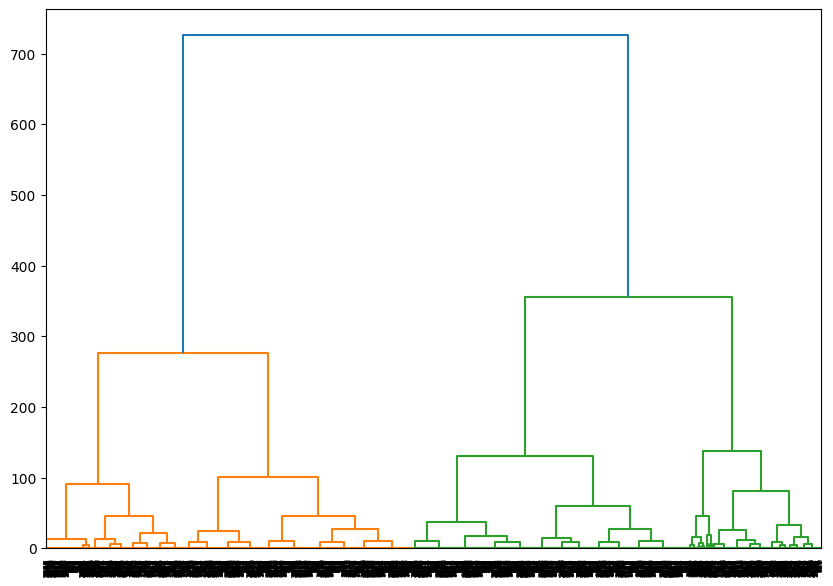

In [25]:
# Group the DataFrame by 'Customer_ID' and compute the mean of 'Monthly_Income_INR'
coustom = df.groupby('Customer_ID')['Age'].mean().values.reshape(-1, 1)

# Create the linkage matrix and plot the dendrogram using the correctly imported lowercase 'dendrogram'
plt.figure(figsize=(10, 7))
dendrogram(linkage(coustom, method='ward'))
plt.show()